# 01 · 12-1 momentum on S&P 500 sectors

**Question:** does buying, every month, the 3 sectors that rose the most over the last 12 months (skipping the latest one) beat holding the 9 sectors in equal parts?

**Short answer:** not by any meaningful margin. With 5 bps of costs the result is a tie (Sharpe 0.64 for both), and with 20 bps momentum falls behind. The details and the reasons are at the end.

Rules of this notebook:
- It only imports from `backtester` and presents results; the logic lives in `src/` with its tests.
- The parameters (12-1, top 3, monthly rebalancing) were fixed **before** looking at the results. No other combination has been tried.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from backtester import ProportionalCosts, run_backtest
from backtester.data import load_prices, quality_report
from backtester.report import compare, plot_result
from backtester.strategies import CrossSectionalMomentum
from backtester.strategy import BuyAndHold, EqualWeight

SECTOR_ETFS = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
START, END = "2005-01-01", "2026-10-31"  # fixed end date: reproducible numbers
IMG_DIR = Path("../docs/img")

## 1. Data

Adjusted closes (dividends and splits) from Yahoo Finance for the 9 SPDR sector ETFs that have existed since 1998.

In [2]:
prices = load_prices(SECTOR_ETFS, start=START, end=END)
print(f"{prices.shape[0]} sessions, from {prices.index[0].date()} to {prices.index[-1].date()}")
quality_report(prices)

5492 sessions, from 2005-01-03 to 2026-10-30


,First date,Last date,Observations,Internal NaNs,Non-positive prices,Largest |daily return|,Largest gap (days)
XLB,2005-01-03,2026-10-30,5492,0,0,0.140576,5
XLE,2005-01-03,2026-10-30,5492,0,0,0.201412,5
XLF,2005-01-03,2026-10-30,5492,0,0,0.166667,5
XLI,2005-01-03,2026-10-30,5492,0,0,0.126512,5
XLK,2005-01-03,2026-10-30,5492,0,0,0.138983,5
XLP,2005-01-03,2026-10-30,5492,0,0,0.093956,5
XLU,2005-01-03,2026-10-30,5492,0,0,0.127934,5
XLV,2005-01-03,2026-10-30,5492,0,0,0.120547,5
XLY,2005-01-03,2026-10-30,5492,0,0,0.126686,5


**What the check shows**

- All 9 ETFs have the same 5,492 sessions: no differing start dates and no internal NaNs.
- The largest gap between sessions is 5 calendar days and it happens twice, both real market closures: January 2, 2007 (Gerald Ford's funeral) and Hurricane Sandy in October 2012.
- The largest daily moves (between 9% and 20%) are plausible for sectors in a crisis, not data errors.
- **One problem that did show up:** on the first download Yahoo failed for XLB and returned the whole column empty, without raising an error. The backtest ran anyway with 8 sectors, and the broken cache would have been reused forever. `load_prices` now raises an error if any ticker is missing.

**Limitations of the universe**

- The two newest sectors are missing: XLRE (real estate, 2015) and XLC (communication services, 2018). They are left out to keep the universe constant. When they were created, their companies left XLF, XLK and XLY, so the composition of those three changed along the way.
- Yahoo's adjusted closes are recomputed with every dividend, so the numbers may vary slightly if the data is downloaded again later.

## 2. Backtest

- **12-1 momentum:** at each month end, the 3 sectors with the highest return between *t-252* and *t-21* sessions, in equal parts. Costs of 5 bps per unit of turnover.
- **Equal weight:** the 9 sectors at 11.1% each, also rebalanced at each month end and with the same 5 bps.
- **Buy & hold** (only as a reference in the metrics table): buy the 9 sectors in equal parts at the start and never trade again.

Between rebalances the engine does not trade: the weights drift with prices, and going back to the target counts as turnover and pays costs.

A caveat about the comparison: momentum needs a year of history, so during 2005 it sits in cash. To avoid mixing "momentum" with "a year uninvested", all series are trimmed to the first day on which momentum holds a position.

In [3]:
def run_momentum(bps: float):
    return run_backtest(
        prices, CrossSectionalMomentum(top_n=3), ProportionalCosts(bps=bps), rebalance="ME"
    )


start = run_momentum(5).first_active
momentum = run_momentum(5).since(start)
benchmark = run_backtest(prices, EqualWeight(), ProportionalCosts(bps=5), rebalance="ME").since(
    start
)
# Reference: buy the 9 sectors in equal parts the day before `start` and never trade again.
entry = prices.index[prices.index.get_loc(start) - 1]
buy_hold = run_backtest(prices.loc[entry:], BuyAndHold(), ProportionalCosts(bps=5)).since(start)
print(f"Period compared: {start.date()} to {prices.index[-1].date()}")

Period compared: 2006-02-01 to 2026-10-30


## 3. Equity and drawdown

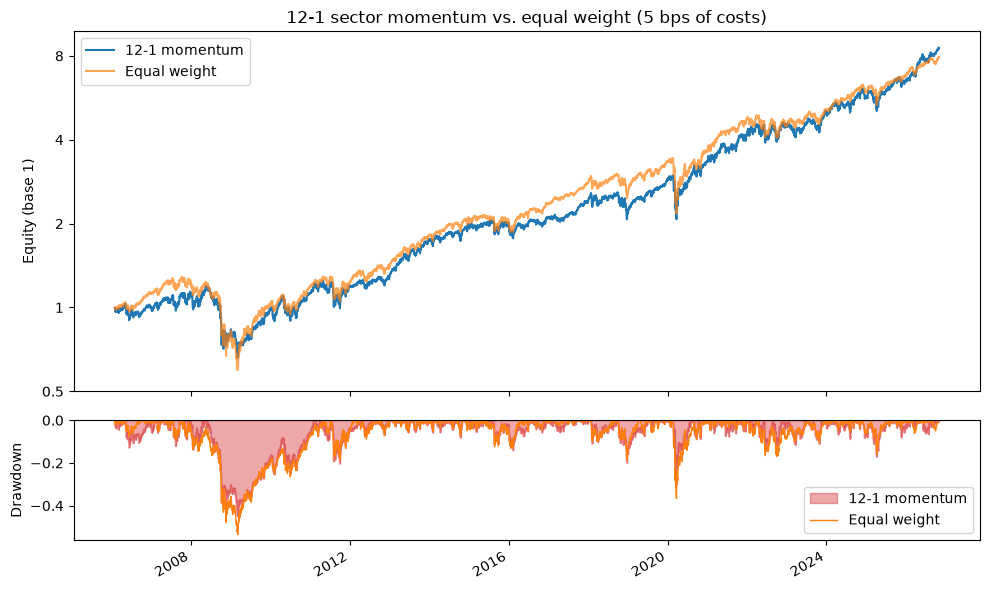

In [4]:
fig = plot_result(
    momentum,
    benchmark,
    title="12-1 sector momentum vs. equal weight (5 bps of costs)",
    labels=("12-1 momentum", "Equal weight"),
)
ax_equity = fig.axes[0]
ax_equity.set_yscale("log")  # 20 years of compounding: on a linear scale 2008 is invisible
ax_equity.set_yticks([0.5, 1, 2, 4, 8], labels=["0.5", "1", "2", "4", "8"])
ax_equity.minorticks_off()
fig.tight_layout()
IMG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG_DIR / "sector_momentum.png", dpi=150)
plt.show()

## 4. Metrics

In [5]:
metrics = compare({"12-1 momentum": momentum, "Equal weight": benchmark, "Buy & hold": buy_hold})
metrics.round(3)

,12-1 momentum,Equal weight,Buy & hold
CAGR,0.109,0.105,0.105
Annual volatility,0.188,0.183,0.180
Sharpe,0.645,0.637,0.648
Sortino,0.907,0.892,0.908
Max drawdown,-0.450,-0.535,-0.517
Calmar,0.242,0.196,0.204
Annual turnover,5.250,0.294,0.048
Annual costs,0.003,0.000,0.000


## 5. Sensitivity to costs

The same momentum with 0, 5 and 20 bps per unit of turnover. The benchmark only moves 0.3 times the portfolio per year to get back to equal parts, so its costs are negligible.

In [6]:
by_cost = {f"Momentum {bps} bps": run_momentum(bps).since(start) for bps in (0, 5, 20)}
compare({**by_cost, "Equal weight": benchmark}).round(3)

,Momentum 0 bps,Momentum 5 bps,Momentum 20 bps,Equal weight
CAGR,0.112,0.109,0.100,0.105
Annual volatility,0.188,0.188,0.188,0.183
Sharpe,0.659,0.645,0.603,0.637
Sortino,0.927,0.907,0.847,0.892
Max drawdown,-0.449,-0.450,-0.452,-0.535
Calmar,0.249,0.242,0.222,0.196
Annual turnover,5.250,5.250,5.250,0.294
Annual costs,0.000,0.003,0.010,0.000


## 6. Year by year

Annual return of each portfolio and the difference (momentum minus equal weight). 2006 starts in February and 2026 ends in October.

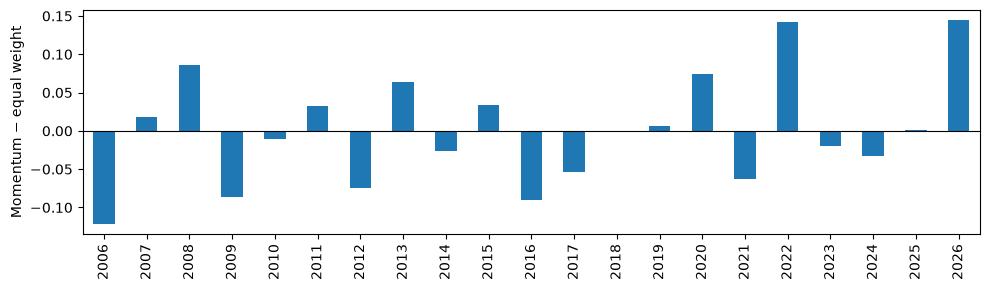

Momentum wins 10 of 21 years.
Daily correlation with the benchmark: 0.90


,12-1 momentum,Equal weight,Difference
Date,,,
2006,0.004,0.125,-0.122
2007,0.113,0.095,0.018
2008,-0.269,-0.355,0.085
2009,0.195,0.281,-0.086
2010,0.150,0.161,-0.010
2011,0.064,0.031,0.033
2012,0.073,0.147,-0.075
2013,0.372,0.308,0.064
2014,0.107,0.133,-0.026


In [7]:
def yearly(result):
    return (1 + result.returns).groupby(result.returns.index.year).prod() - 1


by_year = pd.DataFrame({"12-1 momentum": yearly(momentum), "Equal weight": yearly(benchmark)})
by_year["Difference"] = by_year["12-1 momentum"] - by_year["Equal weight"]

ax = by_year["Difference"].plot(kind="bar", figsize=(10, 3), color="tab:blue")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Momentum − equal weight")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

wins = int((by_year["Difference"] > 0).sum())
corr = momentum.returns.corr(benchmark.returns)
print(f"Momentum wins {wins} of {len(by_year)} years.")
print(f"Daily correlation with the benchmark: {corr:.2f}")
by_year.round(3)

## 7. Interpretation

**Sector momentum does not beat equal weight by any meaningful margin.**

| | 12-1 momentum (5 bps) | Equal weight | Buy & hold |
|---|---|---|---|
| CAGR | 10.9% | 10.5% | 10.5% |
| Sharpe | 0.64 | 0.64 | 0.65 |
| Max drawdown | −45.0% | −53.5% | −51.7% |

- **Return:** 0.4 points more per year, with slightly more volatility. The Sharpe is identical to the second decimal.
- **Costs:** the strategy turns the portfolio over about 5 times a year. Without costs it beats the benchmark by 0.7 points; with 5 bps, by 0.4; with 20 bps it is 0.5 behind. The gross edge is the same size as realistic costs.
- **Year by year:** it wins 10 of 21 years, in other words a coin flip. The edge is concentrated in four years (2026, 2022, 2008 and 2020); the other 17, taken together, subtract.
- **Drawdown:** the only visible difference is the max drawdown, 8.5 points smaller. But that is a single episode (2008), and one observation does not show that the strategy protects in downturns.

- **Buy & hold:** never rebalancing gives practically the same as rebalancing every month (10.5% in both cases), even though the portfolio ends up far from equal parts: XLK weighs 31% at the end. Momentum does not clearly beat it either.
- **Effect of modelling weight drift:** the engine used to rebalance every day at no cost. With that fixed, the figures drop a little for both portfolios (momentum from 11.0% to 10.9% CAGR; equal weight from 10.7% to 10.5%; Sharpe from 0.65 to 0.64 for both) and the conclusion does not change.

With 21 years and a difference of this size I cannot claim the edge is different from zero. Phase 3 of the project (block bootstrap and Sharpe confidence intervals) is there to quantify it.

### Why this can happen

1. **A very small, highly correlated universe.** With 9 sectors, the "top 3" is a third of the market. The resulting portfolio has a correlation of 0.90 with the benchmark: it is mostly market beta with a small sector bet on top. Momentum in the literature (Jegadeesh and Titman, 1993) is measured on hundreds of stocks with a long-short portfolio.
2. **Long positions only.** The classic momentum premium is winners minus losers. Here only the winners are bought, so the short side of the premium is not captured.
3. **Market turns.** Momentum is late to rebounds: in 2009 it loses almost 9 points to the benchmark, and it lags again in 2012 and 2016. It wins when the trend lasts (2008, 2020, 2022).
4. **The benchmark is demanding.** Rebalancing to equal parts sells what goes up and buys what goes down, the exact opposite of momentum.
5. **A single historical path.** There are 21 years and one sequence of crises. The result depends on a handful of episodes.

### What cannot be concluded

- That momentum "does not work": only that this version, in this universe and with these costs, adds no clear value over equal weight.
- That the smaller max drawdown is a property of the strategy.

### Next steps

- Try the long-short version and measure statistical significance (phase 3).